<a href="https://colab.research.google.com/github/smruthi215/DLG--LAB/blob/main/lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

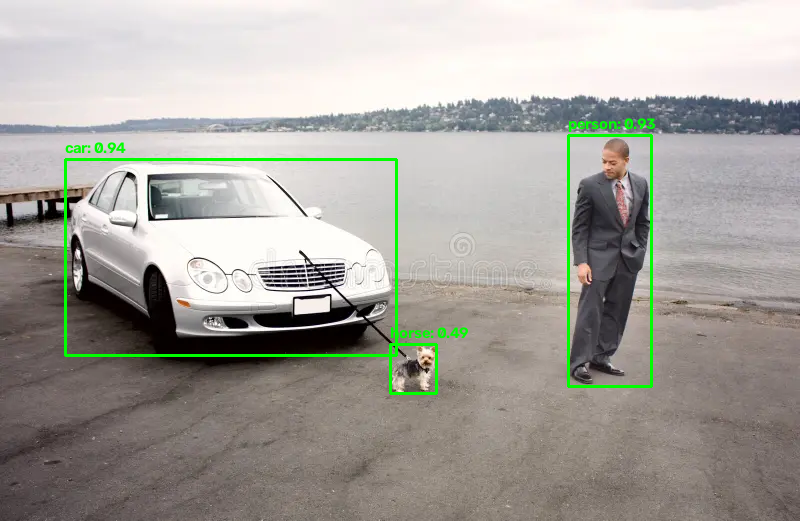

In [ ]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
import os
from google.colab.patches import cv2_imshow

# 1. Load a pre-trained object detection model from TensorFlow Hub
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)

# COCO labels list
COCO_CLASSES = [
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat',
    'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack',
    'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
    'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop',
    'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

def detect_objects_with_boxes(img_path, model):
    orig_image = cv2.imread(img_path)
    if orig_image is None:
        raise FileNotFoundError(f"Image not found at {img_path}")

    # Convert image to tensor
    image_tensor = tf.convert_to_tensor(orig_image, dtype=tf.uint8)
    image_tensor = tf.expand_dims(image_tensor, axis=0)

    # Run detection
    results = model(image_tensor)

    # Extract results
    boxes = results['detection_boxes'][0].numpy()
    classes = results['detection_classes'][0].numpy().astype(int)
    scores = results['detection_scores'][0].numpy()

    h, w, _ = orig_image.shape

    for i in range(len(scores)):
        if scores[i] > 0.4:  # Threshold limit
            ymin, xmin, ymax, xmax = boxes[i]
            (left, right, top, bottom) = (int(xmin * w), int(xmax * w), int(ymin * h), int(ymax * h))

            # Draw bounding box
            cv2.rectangle(orig_image, (left, top), (right, bottom), (0, 255, 0), 2)

            # Put class name and confidence score
            class_id = classes[i] - 1
            class_name = COCO_CLASSES[class_id] if 0 <= class_id < len(COCO_CLASSES) else "unknown"
            label = f"{class_name}: {scores[i]:.2f}"
            cv2.putText(orig_image, label, (left, max(18, top - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    return orig_image

# Pointing to your selected image
image_path = "/content/example.webp"

# Detect objects and draw bounding boxes
result_image = detect_objects_with_boxes(image_path, detector)

# Display output inside Colab
cv2_imshow(result_image)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving example.webp to example (1).webp


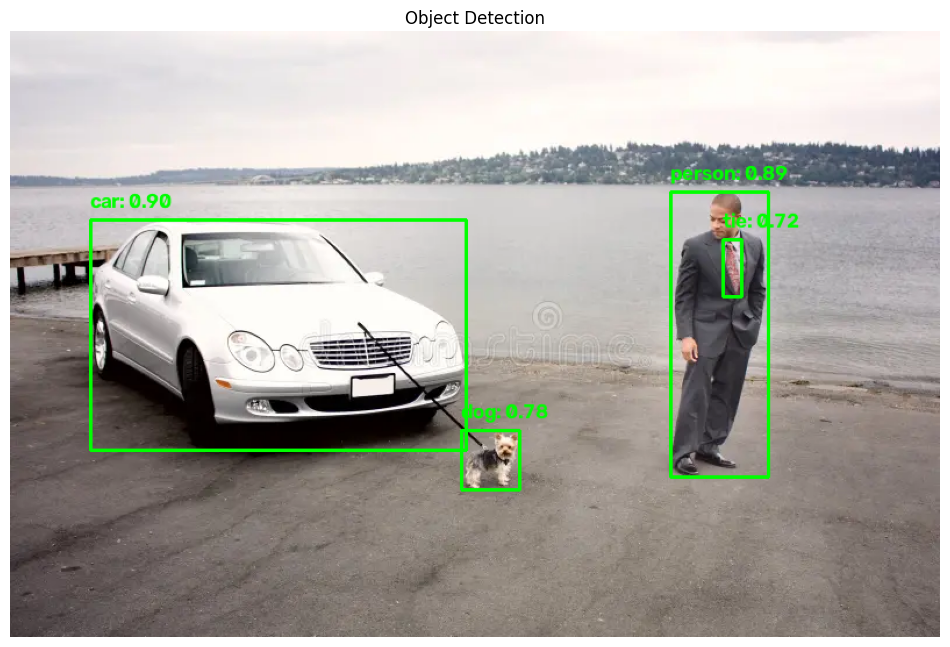

In [ ]:
# Install required packages (run in Google Colab)
!pip -q install ultralytics

import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# Upload an image
uploaded = files.upload()
img_path = next(iter(uploaded.keys()))

# Load image
img = cv2.imread(img_path)

if img is None:
    raise ValueError(f"Could not load image: {img_path}")

# Load a pretrained object detection model
# Downloads pretrained weights on the first run
model = YOLO("yolov8n.pt")

# Run object detection
results = model.predict(
    source=img,
    conf=0.5,
    verbose=False
)

# Draw bounding boxes and class labels
result_img = img.copy()

for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        label = f"{model.names[class_id]}: {confidence:.2f}"

        cv2.rectangle(
            result_img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result_img,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

# Display the result (works in Colab and Jupyter)
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.title("Object Detection")
plt.axis("off")
plt.show()